# Land Type Classification Using Deep Learning and Satellite Imagery

This notebook builds a 10-class EuroSAT image classifier with a pretrained ResNet50. Run the cells in order in Google Colab. The training cell is intentionally separate so you can start training when you are ready.

**Workflow:** data audit and preparation → transfer learning → validation → final test evaluation → saved model and image inference.


## 1. Project Overview

EuroSAT contains 27,000 RGB satellite images across 10 land-cover classes. The target split is 70% training, 15% validation, and 15% testing. ResNet50 expects 224 × 224 inputs, so the original 64 × 64 images will be resized.

In [ ]:
PROJECT_NAME = "Land Type Classification Using Deep Learning and Satellite Imagery"
DATASET_NAME = "EuroSAT"
NUM_CLASSES = 10
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42

print(PROJECT_NAME)
print(f"Dataset: {DATASET_NAME} | Classes: {NUM_CLASSES} | Input: {IMAGE_SIZE}x{IMAGE_SIZE} RGB")
print(f"Split: 70% train / 15% validation / 15% test | Batch size: {BATCH_SIZE}")

Land Type Classification Using Deep Learning and Satellite Imagery
Dataset: EuroSAT | Classes: 10 | Input: 224x224 RGB
Split: 70% train / 15% validation / 15% test | Batch size: 32


## 2. Environment Setup

Import the project dependencies, set reproducibility controls, and select the available GPU when Colab provides one. Colab already includes the required packages in its standard PyTorch runtime.

In [ ]:
import copy
import random
import sys
import time
from pathlib import Path
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms
from torchvision.datasets import EuroSAT

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("/content/eurosat_data") if Path("/content").exists() else Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available; training will use CPU and take longer.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


## 3. Dataset Collection

Load EuroSAT through torchvision. The download is performed only if the dataset is not already present in the selected data directory.

In [ ]:
dataset = EuroSAT(root=str(DATA_DIR), download=True)
class_names = dataset.classes
targets = np.asarray(dataset.targets, dtype=np.int64)

print("Dataset downloaded and loaded.")
print("Total images:", len(dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

100%|██████████| 94.3M/94.3M [00:01<00:00, 77.0MB/s]


Dataset downloaded and loaded.
Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 4. Exploratory Data Analysis (EDA)

Check the number of images in each class and visualize the distribution. EuroSAT is close to balanced, with modest differences in a few class counts.

                  Class  Number of Images
0            AnnualCrop              3000
1                Forest              3000
2  HerbaceousVegetation              3000
3               Highway              2500
4            Industrial              2500
5               Pasture              2000
6         PermanentCrop              2500
7           Residential              3000
8                 River              2500
9               SeaLake              3000


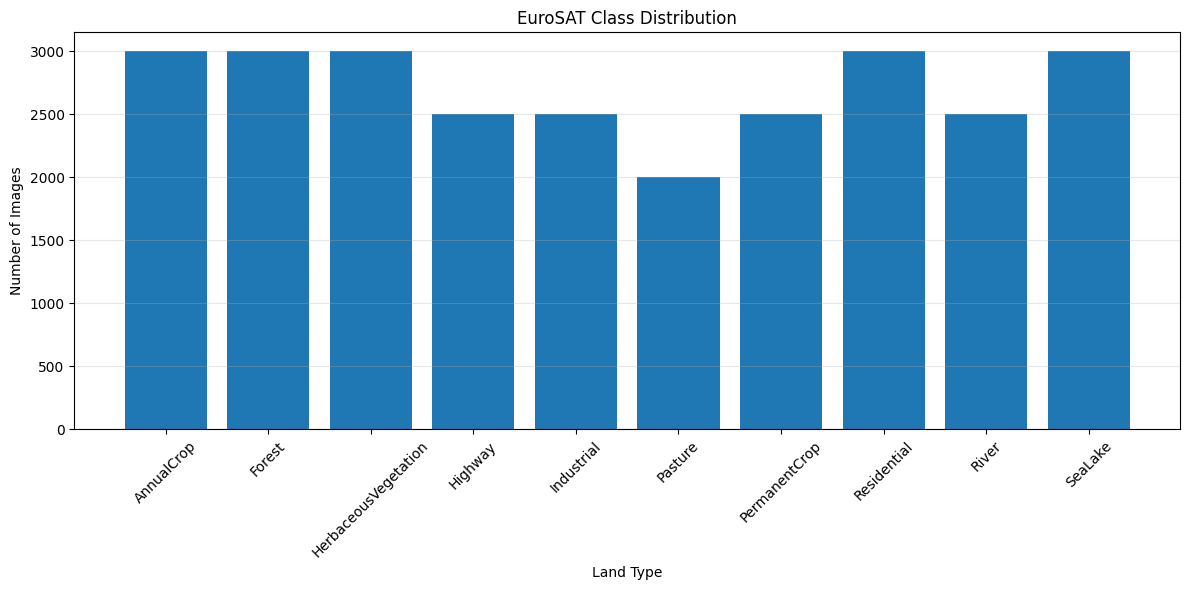

In [ ]:
class_counts = pd.Series(dataset.targets).value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": dataset.classes,
    "Number of Images": class_counts.values
})

print(class_distribution)

plt.figure(figsize=(12, 6))
plt.bar(
    class_distribution["Class"],
    class_distribution["Number of Images"]
)
plt.title("EuroSAT Class Distribution")
plt.xlabel("Land Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Image Understanding

Display one representative image from each class. The examples remain in their original 64 × 64 RGB form at this stage.

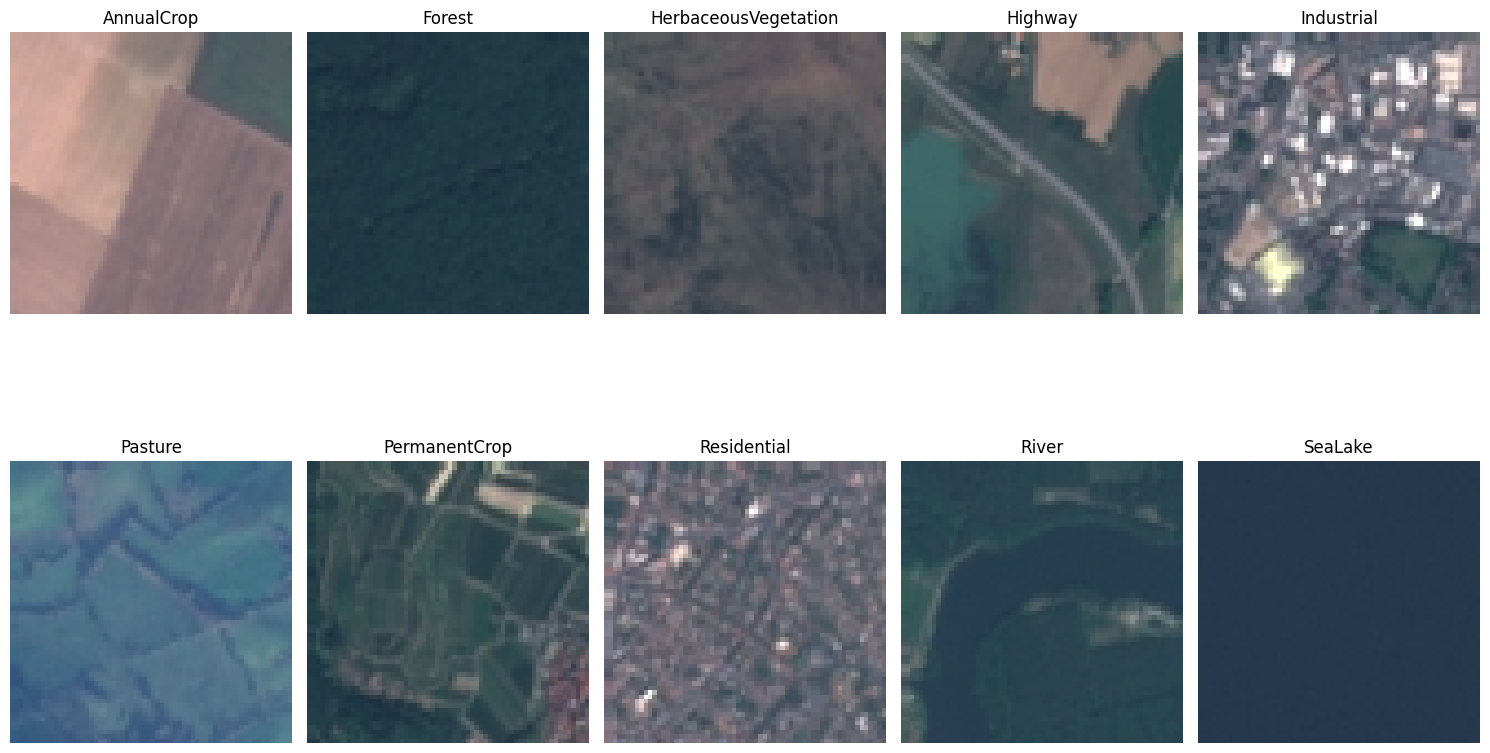

In [ ]:
class_images = defaultdict(list)
for index, label in enumerate(targets):
    class_images[int(label)].append(index)

plt.figure(figsize=(15, 10))
for class_id, class_name in enumerate(class_names):
    image_index = random.choice(class_images[class_id])
    image, _ = dataset[image_index]
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

Inspect a raw sample before defining model transforms. EuroSAT images are RGB PIL images with 8-bit pixel values; resizing and normalization are applied in the transformation stage.

In [ ]:
sample_image, sample_label = dataset[0]
image_array = np.asarray(sample_image)

print("Image class:", class_names[sample_label])
print("Image mode:", sample_image.mode)
print("Image shape:", image_array.shape)
print("Image data type:", image_array.dtype)
print("Pixel range:", int(image_array.min()), "to", int(image_array.max()))

assert sample_image.mode == "RGB", "Expected an RGB image."
assert image_array.shape == (64, 64, 3), "Expected a 64x64 RGB EuroSAT image."

Image class: AnnualCrop
Image mode: RGB
Image shape: (64, 64, 3)
Image data type: uint8
Pixel range: 82 to 204


## 7. Dataset Splitting

Create reproducible stratified splits so each subset keeps approximately the same class distribution. The test set is held out until the final evaluation.

In [ ]:
all_indices = np.arange(len(targets))

test_count = int(round(0.15 * len(all_indices)))
val_count = int(round(0.15 * len(all_indices)))

train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=test_count,
    random_state=SEED,
    stratify=targets,
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=val_count,
    random_state=SEED,
    stratify=targets[train_val_indices],
)

split_summary = pd.DataFrame({
    "Class": class_names,
    "Train": np.bincount(targets[train_indices], minlength=NUM_CLASSES),
    "Validation": np.bincount(targets[val_indices], minlength=NUM_CLASSES),
    "Test": np.bincount(targets[test_indices], minlength=NUM_CLASSES),
})

print(f"Training images:   {len(train_indices):,}")
print(f"Validation images: {len(val_indices):,}")
print(f"Testing images:    {len(test_indices):,}")
display(split_summary)

assert (len(train_indices), len(val_indices), len(test_indices)) == (18_900, 4_050, 4_050)

Training images:   18,900
Validation images: 4,050
Testing images:    4,050


,Class,Train,Validation,Test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


## 8. Image Transformations

Resize each image to 224 × 224 and apply ImageNet normalization expected by pretrained ResNet50 weights. Random flips and rotation are used only for training; validation and test transforms are deterministic.

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Training and evaluation transforms are ready.")

Training and evaluation transforms are ready.


## 9. Dataset Preparation

Create separate dataset views so random augmentation is applied to training examples only. Each view uses the same underlying EuroSAT file ordering as the stratified indices.

In [ ]:
train_data = EuroSAT(root=str(DATA_DIR), download=False, transform=train_transform)
eval_data = EuroSAT(root=str(DATA_DIR), download=False, transform=eval_transform)

train_set = Subset(train_data, train_indices.tolist())
val_set = Subset(eval_data, val_indices.tolist())
test_set = Subset(eval_data, test_indices.tolist())

assert train_data.classes == class_names
assert eval_data.classes == class_names
print("Prepared dataset sizes:", len(train_set), len(val_set), len(test_set))

Prepared dataset sizes: 18900 4050 4050


## 10. DataLoader Creation

Load batches of 32 images. Pinned memory is enabled on GPU systems, while a small worker count keeps Colab memory use manageable.

In [ ]:
NUM_WORKERS = 2 if device.type == "cuda" else 0
loader_settings = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
}

train_loader = DataLoader(train_set, shuffle=True, **loader_settings)
val_loader = DataLoader(val_set, shuffle=False, **loader_settings)
test_loader = DataLoader(test_set, shuffle=False, **loader_settings)

images_batch, labels_batch = next(iter(train_loader))
print("Image batch shape:", tuple(images_batch.shape))
print("Label batch shape:", tuple(labels_batch.shape))
print("Batch size:", BATCH_SIZE)
del images_batch, labels_batch

Image batch shape: (32, 3, 224, 224)
Label batch shape: (32,)
Batch size: 32


## 11. Model Building (ResNet50)

Initialize ResNet50 with ImageNet pretrained weights and replace its final fully connected layer with a 10-class classifier. The first run may download the pretrained weights.

In [ ]:
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, NUM_CLASSES)
model = model.to(device)

print("Architecture: ResNet50")
print("Output classes:", model.fc.out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 249MB/s]

Architecture: ResNet50
Output classes: 10
Device: cuda


## 12. Transfer Learning Configuration

Freeze the earlier feature extractor and fine-tune the final ResNet block (`layer4`) together with the new classifier. This reduces trainable parameters and GPU memory use while adapting high-level features to EuroSAT.

In [ ]:
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.layer4.parameters():
    parameter.requires_grad = True
for parameter in model.fc.parameters():
    parameter.requires_grad = True

trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,}")

Trainable parameters: 14,985,226 / 23,528,522


## 13. Loss Function and Optimizer

Use multiclass cross-entropy and Adam. Only parameters enabled for fine-tuning are passed to the optimizer.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    (parameter for parameter in model.parameters() if parameter.requires_grad),
    lr=1e-4,
)
print("Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4")

Loss: CrossEntropyLoss | Optimizer: Adam | Learning rate: 1e-4


## 14. Model Training

Define reusable epoch functions. Training loss and accuracy are averaged over examples, and the frozen backbone's BatchNorm layers keep their pretrained running statistics.

In [ ]:
def run_epoch(loader, training=False):
    model.train(training)
    if training:
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d) and not any(
                parameter.requires_grad for parameter in module.parameters()
            ):
                module.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        batch_count = labels.size(0)
        total_loss += loss.item() * batch_count
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_count

    return total_loss / total, correct / total

print("Training and validation epoch functions are ready.")

Training and validation epoch functions are ready.


## 15. Validation and Performance Monitoring

This is the training cell. It runs one training and one validation pass per epoch, tracks loss and accuracy, and retains the weights with the lowest validation loss. Execute it manually when ready; no training is started by the setup cells.

Epoch 01/15 | train loss 0.3261, accuracy 0.9110 | val loss 0.0953, accuracy 0.9706 | 12.3s
Epoch 02/15 | train loss 0.0979, accuracy 0.9679 | val loss 0.0752, accuracy 0.9758 | 8.8s
Epoch 03/15 | train loss 0.0677, accuracy 0.9764 | val loss 0.0781, accuracy 0.9728 | 10.5s
Epoch 04/15 | train loss 0.0510, accuracy 0.9827 | val loss 0.0647, accuracy 0.9793 | 9.4s
Epoch 05/15 | train loss 0.0446, accuracy 0.9854 | val loss 0.0571, accuracy 0.9822 | 10.4s
Epoch 06/15 | train loss 0.0321, accuracy 0.9898 | val loss 0.0559, accuracy 0.9849 | 10.1s
Epoch 07/15 | train loss 0.0284, accuracy 0.9905 | val loss 0.0561, accuracy 0.9847 | 10.2s
Epoch 08/15 | train loss 0.0271, accuracy 0.9907 | val loss 0.0692, accuracy 0.9810 | 10.6s
Epoch 09/15 | train loss 0.0216, accuracy 0.9932 | val loss 0.0675, accuracy 0.9817 | 10.6s
Epoch 10/15 | train loss 0.0163, accuracy 0.9950 | val loss 0.0651, accuracy 0.9825 | 10.4s
Early stopping: validation loss did not improve for 4 epochs.
Best epoch: 6 | best

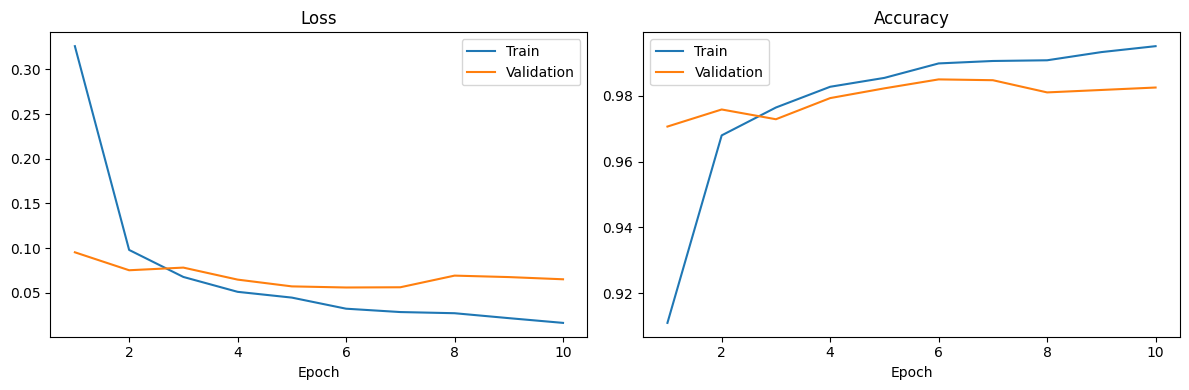

In [ ]:
NUM_EPOCHS = 15
PATIENCE = 4
best_val_loss = float("inf")
best_epoch = 0
best_model_state = None
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - epoch_start
    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.4f} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.4f} | "
        f"{elapsed:.1f}s"
    )
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

if best_model_state is None:
    raise RuntimeError("Training did not produce a best model checkpoint.")
model.load_state_dict(best_model_state)
print(f"Best epoch: {best_epoch} | best validation loss: {best_val_loss:.4f}")

epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 16. Model Evaluation

Restore the best validation checkpoint and evaluate the held-out test set once. Do not use these test results to tune the model.

In [ ]:
if best_model_state is None:
    raise RuntimeError("Run the training cell before evaluating the model.")
model.load_state_dict(best_model_state)
model.eval()

all_labels = []
all_predictions = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)
print(f"Test accuracy: {test_accuracy:.4f}")

Test accuracy: 0.9820


## 17. Confusion Matrix

Show how often each true class is predicted as each class. Rows are true labels and columns are predicted labels.

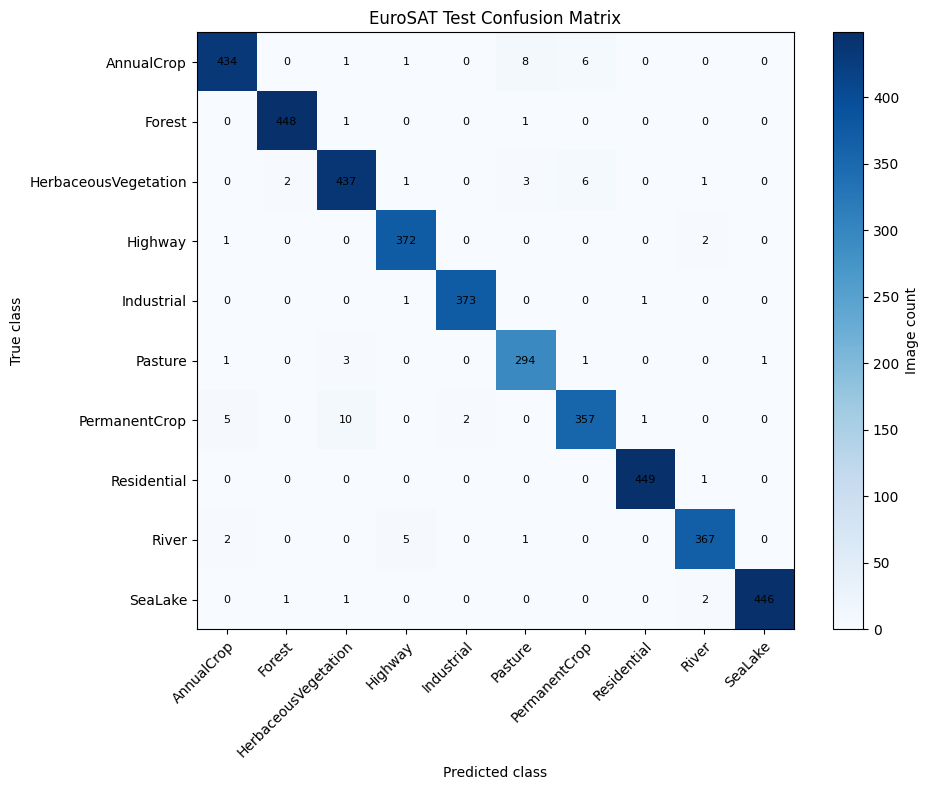

In [ ]:
confusion = confusion_matrix(all_labels, all_predictions, labels=np.arange(NUM_CLASSES))
fig, ax = plt.subplots(figsize=(10, 8))
image_plot = ax.imshow(confusion, cmap="Blues")
ax.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="EuroSAT Test Confusion Matrix",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        ax.text(column, row, str(confusion[row, column]), ha="center", va="center", fontsize=8)
fig.colorbar(image_plot, ax=ax, label="Image count")
plt.tight_layout()
plt.show()

## 18. Classification Report

Report per-class precision, recall, and F1-score, together with macro and weighted averages.

In [ ]:
report = classification_report(
    all_labels,
    all_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    digits=4,
    zero_division=0,
)
print(report)

                      precision    recall  f1-score   support

          AnnualCrop     0.9797    0.9644    0.9720       450
              Forest     0.9933    0.9956    0.9945       450
HerbaceousVegetation     0.9647    0.9711    0.9679       450
             Highway     0.9789    0.9920    0.9854       375
          Industrial     0.9947    0.9947    0.9947       375
             Pasture     0.9577    0.9800    0.9687       300
       PermanentCrop     0.9649    0.9520    0.9584       375
         Residential     0.9956    0.9978    0.9967       450
               River     0.9839    0.9787    0.9813       375
             SeaLake     0.9978    0.9911    0.9944       450

            accuracy                         0.9820      4050
           macro avg     0.9811    0.9817    0.9814      4050
        weighted avg     0.9820    0.9820    0.9820      4050



## 19. Model Saving

Save the best model weights and the class/preprocessing metadata needed to reproduce predictions. In Colab, download this file or save it to mounted Google Drive if you need it after the runtime ends.

In [ ]:
MODEL_PATH = Path("best_resnet50_eurosat.pth")
checkpoint = {
    "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
    "best_epoch": best_epoch,
    "best_validation_loss": best_val_loss,
}
torch.save(checkpoint, MODEL_PATH)
print("Saved model to:", MODEL_PATH.resolve())

Saved model to: /content/best_resnet50_eurosat.pth


## 20. Model Loading and Inference

Rebuild the model architecture without downloading weights, load the saved checkpoint, and define a prediction function that applies the same evaluation preprocessing.

In [ ]:
loaded_checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=True)
loaded_class_names = loaded_checkpoint["class_names"]
loaded_model = models.resnet50(weights=None)
loaded_model.fc = nn.Linear(loaded_model.fc.in_features, len(loaded_class_names))
loaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
loaded_model = loaded_model.to(device).eval()

inference_transform = transforms.Compose([
    transforms.Resize((loaded_checkpoint["image_size"], loaded_checkpoint["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=loaded_checkpoint["imagenet_mean"],
        std=loaded_checkpoint["imagenet_std"],
    ),
])

def classify_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = inference_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        probabilities = torch.softmax(loaded_model(image_tensor), dim=1)[0]
    predicted_index = int(probabilities.argmax().item())
    return loaded_class_names[predicted_index], float(probabilities[predicted_index].item())

print("Loaded model ready for single-image inference.")

Loaded model ready for single-image inference.


## 21. Testing with New Satellite Images

Upload one or more RGB satellite images in Google Colab. The model returns its most likely land-cover class and the associated softmax score.

In [ ]:
from google.colab import files

uploaded_files = files.upload()
for filename in uploaded_files:
    predicted_class, confidence = classify_image(filename)
    print(f"{filename}: {predicted_class} (score: {confidence:.3f})")

Saving images-2.jpg to images-2.jpg
images-2.jpg: River (score: 0.818)


## 22. Final Conclusion

After running the notebook in order, you will have a reproducible EuroSAT training pipeline, a validation-selected ResNet50 checkpoint, final held-out test metrics, and a function for classifying new satellite images. Record the observed metrics in your project report after the final evaluation.

In [ ]:
if "test_accuracy" in globals():
    print(f"Final held-out test accuracy: {test_accuracy:.4f}")
    print("See the classification report and confusion matrix above for detailed results.")
else:
    print("Run the training and evaluation cells to generate final test results.")
print("Inference function: classify_image(image_path)")

Final held-out test accuracy: 0.9820
See the classification report and confusion matrix above for detailed results.
Inference function: classify_image(image_path)
